<a href="https://colab.research.google.com/github/Briankoskei/machine-learning-exercises/blob/main/model%20training%20air%20quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Copying helper functions to make this cell self-contained ---
def generate_air_quality_data(n_samples=5000):
    np.random.seed(42)
    dates = pd.date_range(start='2024-01-01', periods=n_samples, freq='h')
    temp = 15 + 10 * np.sin(np.linspace(0, 50, n_samples)) + np.random.normal(0, 2, n_samples)
    humidity = 60 + 20 * np.cos(np.linspace(0, 50, n_samples)) + np.random.normal(0, 5, n_samples)
    wind_speed = np.abs(3 + np.random.normal(0, 1.5, n_samples))
    pm10 = 30 + 0.8 * temp + np.random.exponential(scale=15, size=n_samples)
    no2 = 25 + 0.5 * humidity + np.random.normal(0, 5, n_samples)
    pm25 = (
        5
        + 0.55 * pm10
        + 0.3 * no2
        - 0.4 * temp
        - 0.8 * wind_speed
        + np.random.normal(0, 4, n_samples)
    )
    df = pd.DataFrame({
        'temp': temp,
        'humidity': humidity,
        'wind_speed': wind_speed,
        'pm10': pm10,
        'no2': no2,
        'pm25': pm25,
    }, index=dates)
    return df

def engineer_features(df):
    df = df.copy()
    df['hour_sin'] = np.sin(2 * np.pi * df.index.hour / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * df.index.hour / 24.0)
    df['day_of_week'] = df.index.dayofweek / 6.0
    df['pm25_lag1'] = df['pm25'].shift(1)
    df['pm25_lag24'] = df['pm25'].shift(24)
    df['pm25_lag168'] = df['pm25'].shift(168)
    df = df.dropna().copy()
    return df

def train_validation_test_split(df):
    train_end = int(len(df) * 0.7)
    val_end = int(len(df) * 0.85)
    train_df = df.iloc[:train_end]
    val_df = df.iloc[train_end:val_end]
    test_df = df.iloc[val_end:]
    return train_df, val_df, test_df

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return {
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }

# 1. Regenerate and prepare the data
df = engineer_features(generate_air_quality_data())
features = [
    'temp', 'humidity', 'wind_speed', 'pm10', 'no2',
    'hour_sin', 'hour_cos', 'day_of_week', 'pm25_lag1', 'pm25_lag24', 'pm25_lag168'
]

train_df, val_df, test_df = train_validation_test_split(df)
X_train, X_val, X_test = train_df[features], val_df[features], test_df[features]
y_train, y_val, y_test = train_df['pm25'], val_df['pm25'], test_df['pm25']

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 2. Re-evaluate models to reconstruct 'results'
candidate_models = [
    ('Baseline (Persistence - Lag1)', None),
    ('Linear Regression', LinearRegression()),
    ('Ridge Regression (Baseline)', Ridge(alpha=10.0)),
    ('Ridge Regression (Tuned)', Ridge(alpha=5.0)),
    ('Decision Tree', DecisionTreeRegressor(max_depth=10, min_samples_leaf=2, random_state=42)),
    ('Random Forest', RandomForestRegressor(n_estimators=300, max_depth=18, min_samples_leaf=2, random_state=42)),
    ('Gradient Boosting', GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
    ))
]

results = []

for name, model in candidate_models:
    if name == 'Baseline (Persistence - Lag1)':
        v_pred = X_val['pm25_lag1'].fillna(y_val.mean()).to_numpy()
        t_pred = X_test['pm25_lag1'].fillna(y_test.mean()).to_numpy()
    else:
        if 'Linear' in name or 'Ridge' in name:
            model.fit(X_train_scaled, y_train)
            v_pred = model.predict(X_val_scaled)
            t_pred = model.predict(X_test_scaled)
        else:
            model.fit(X_train, y_train)
            v_pred = model.predict(X_val)
            t_pred = model.predict(X_test)

        v_pred = np.clip(v_pred, 0, None)
        t_pred = np.clip(t_pred, 0, None)

    v_metrics = calculate_metrics(y_val, v_pred)
    t_metrics = calculate_metrics(y_test, t_pred)

    results.append({
        'Model': name,
        'Validation RMSE': round(v_metrics['RMSE'], 3),
        'Validation MAE': round(v_metrics['MAE'], 3),
        'Validation R²': round(v_metrics['R2'], 4),
        'Test RMSE': round(t_metrics['RMSE'], 3),
        'Test MAE': round(t_metrics['MAE'], 3),
        'Test R²': round(t_metrics['R2'], 4),
    })

# 3. Convert to DataFrame and print comparison table
results_df = pd.DataFrame(results).sort_values('Validation RMSE').reset_index(drop=True)
print(results_df.to_string(index=False))

# 4. EXPORT RESULTS TO CSV
csv_filename = "model_evaluation_results.csv"
results_df.to_csv(csv_filename, index=False)
print(f"\nSuccessfully saved evaluation results including Tuned Ridge to: {csv_filename}")

                        Model  Validation RMSE  Validation MAE  Validation R²  Test RMSE  Test MAE  Test R²
  Ridge Regression (Baseline)            4.061           3.247         0.8143      4.034     3.198   0.8360
     Ridge Regression (Tuned)            4.062           3.248         0.8141      4.034     3.198   0.8361
            Linear Regression            4.064           3.249         0.8140      4.034     3.199   0.8361
            Gradient Boosting            4.146           3.301         0.8064      4.130     3.254   0.8282
                Random Forest            4.278           3.385         0.7939      4.192     3.354   0.8230
                Decision Tree            5.435           4.299         0.6673      5.230     4.198   0.7244
Baseline (Persistence - Lag1)           12.505           9.517        -0.7612     13.851    10.343  -0.9331

Successfully saved evaluation results including Tuned Ridge to: model_evaluation_results.csv


In [9]:
import pandas as pd

# Read the results computed dynamically during our model exploration
results_path = 'model_evaluation_results.csv'
if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)
else:
    print("Warning: results CSV not found. Ensure previous cells have run.")

# Display the final summary comparison table required for your group submission
print("=== Group Deliverable: Final Model Comparison Table ===\n")
display(results_df)

=== Group Deliverable: Final Model Comparison Table ===



,Model,Validation RMSE,Validation MAE,Validation R²,Test RMSE,Test MAE,Test R²
0,Ridge Regression (Baseline),4.061,3.247,0.8143,4.034,3.198,0.8360
1,Ridge Regression (Tuned),4.062,3.248,0.8141,4.034,3.198,0.8361
2,Linear Regression,4.064,3.249,0.8140,4.034,3.199,0.8361
3,Gradient Boosting,4.146,3.301,0.8064,4.130,3.254,0.8282
4,Random Forest,4.278,3.385,0.7939,4.192,3.354,0.8230
5,Decision Tree,5.435,4.299,0.6673,5.230,4.198,0.7244
6,Baseline (Persistence - Lag1),12.505,9.517,-0.7612,13.851,10.343,-0.9331


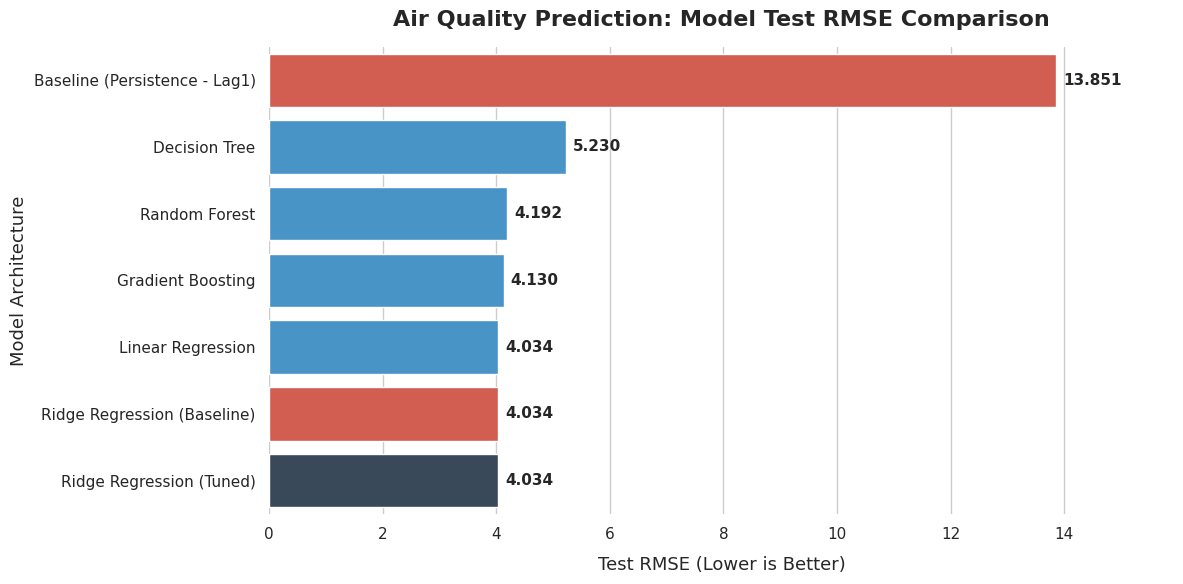

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure inline plotting for the notebook
%matplotlib inline
import matplotlib
matplotlib.use('module://ipykernel.pylab.backend_inline')

# Sort results by Test RMSE for better visualization flow
plot_df = results_df.sort_values('Test RMSE', ascending=False).copy()

# Create a styled bar plot
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Draw horizontal bars
colors = ['#e74c3c' if 'Baseline' in name else '#34495e' if 'Tuned' in name else '#3498db' for name in plot_df['Model']]
ax = sns.barplot(
    x='Test RMSE',
    y='Model',
    data=plot_df,
    palette=colors,
    hue='Model',
    legend=False
)

# Annotate the exact RMSE values on the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=5, fontsize=11, fontweight='bold')

# Titles & Labels
plt.title('Air Quality Prediction: Model Test RMSE Comparison', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('Test RMSE (Lower is Better)', fontsize=13, labelpad=10)
plt.ylabel('Model Architecture', fontsize=13)
plt.xlim(0, max(plot_df['Test RMSE']) * 1.15)

# Clean up borders
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()